In [78]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from cvxopt import matrix, solvers
import math
import matplotlib.pyplot as plt
from utils import *
from class_utils import *
from scipy.spatial.distance import cdist 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from collections import defaultdict
from random import sample
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF

In [3]:
df_spectra = pd.read_csv('spectral_data_all.csv')
df_spectra.drop(columns=['Unnamed: 0'], inplace=True)
df_spectra_flopp = df_spectra.query('data_source == "flopp" or data_source == "flopp_e"').reset_index(drop=True)
df_spectra_flopp = df_spectra_flopp.query('intensity > 0')
df_spectra_flopp = norm_spect(df_spectra_flopp, norm_type='SNV')
df_flopp_pivot = df_spectra_flopp.pivot(index=['file_name', 'polymer', 'data_source'], 
               columns='wavelength', 
               values='intensity').reset_index()
wl_list = df_flopp_pivot.columns[146:-1]
df_flopp_pivot.columns = list(df_flopp_pivot.columns[:3]) + ['wl_' + str(round(x*100)) for x in df_flopp_pivot.columns[3:]]
polymer_list = df_flopp_pivot['polymer'].drop_duplicates().to_numpy()


## Nylon
## Polyester
## Acrylic

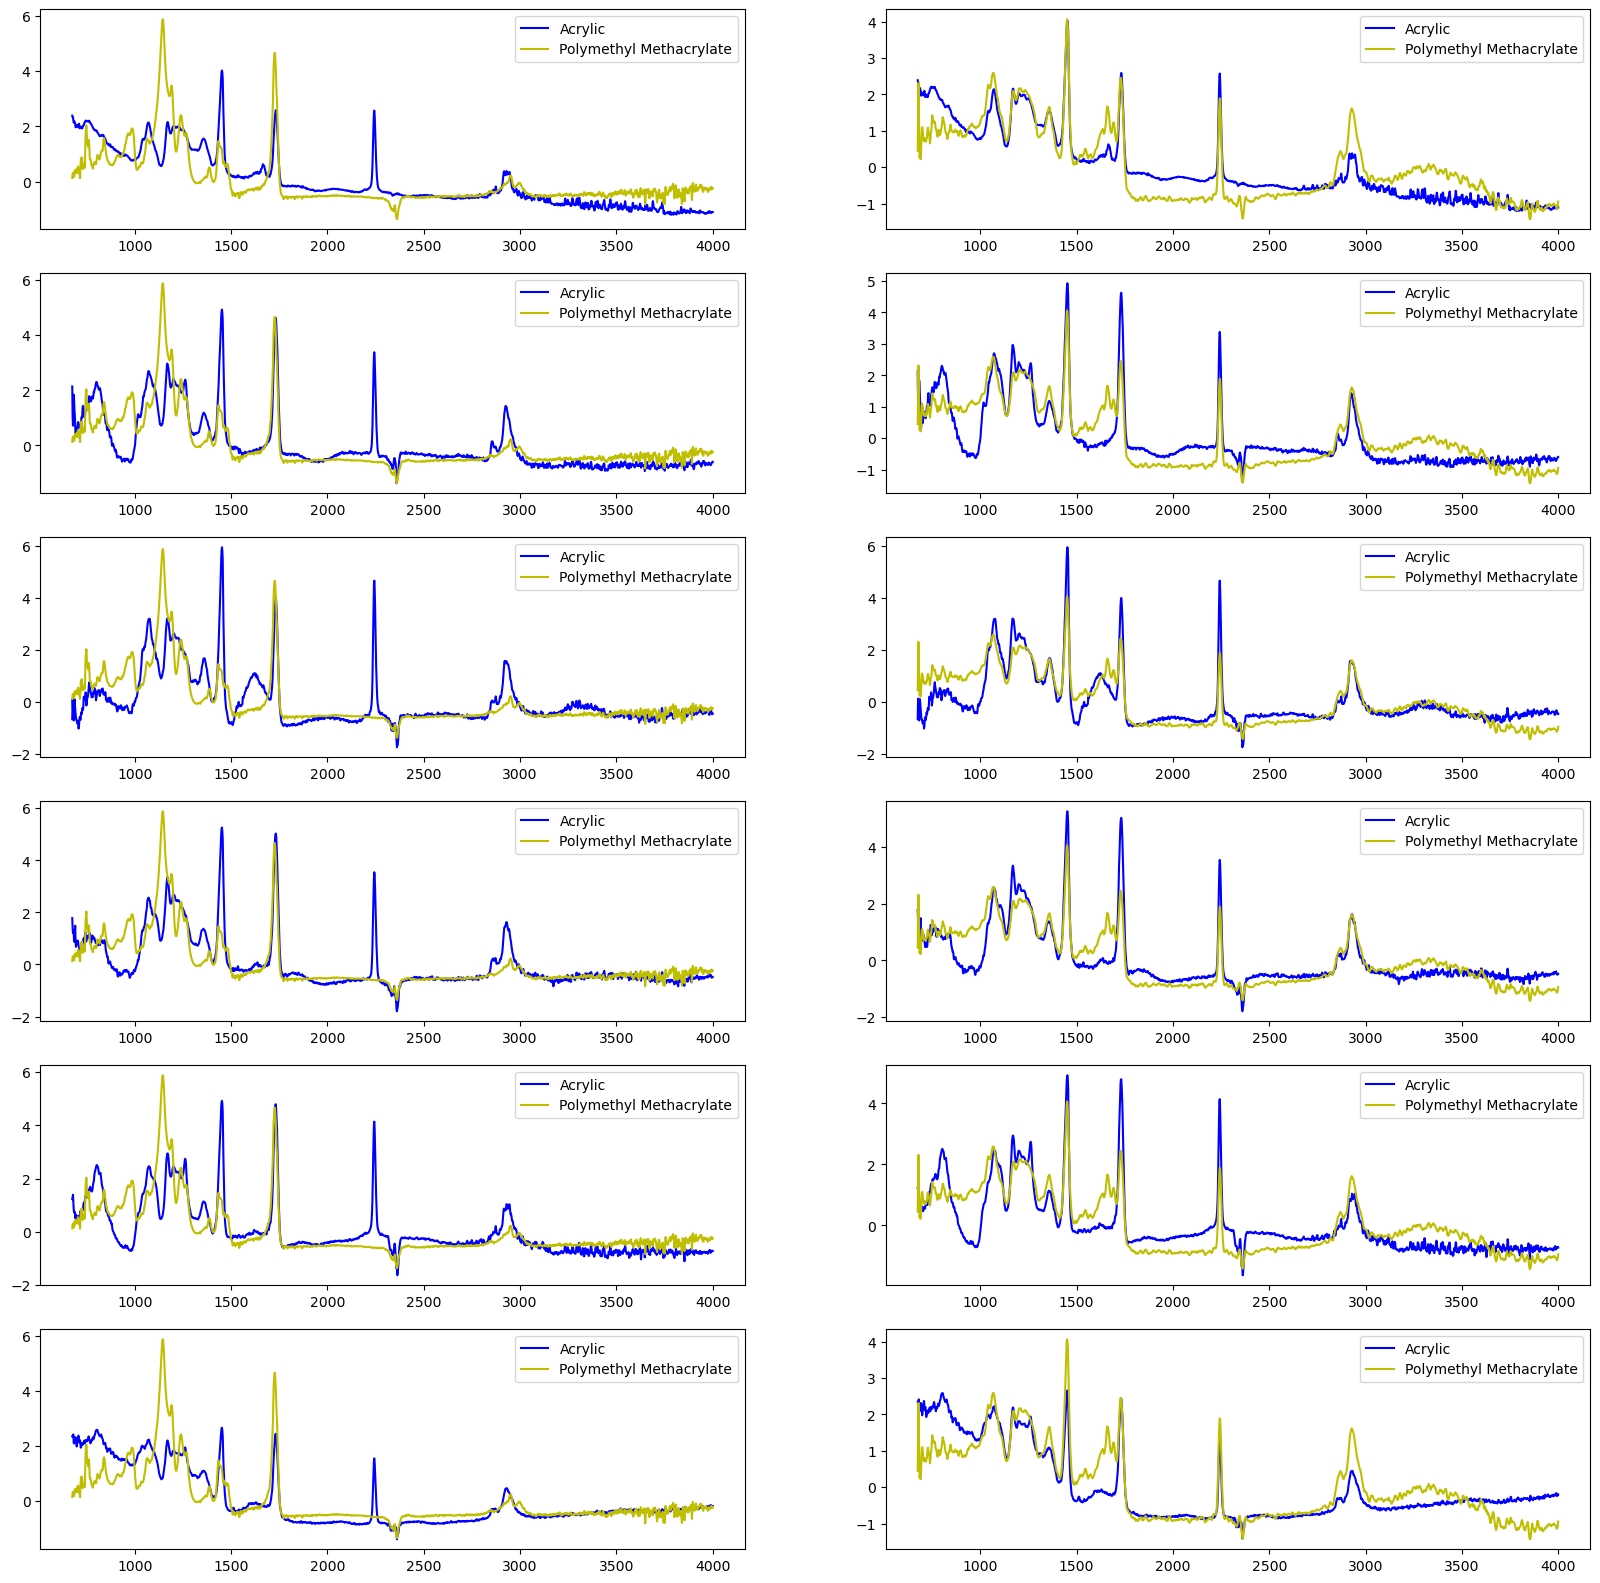

In [68]:
fig, ax = plt.subplots(nrows=6, ncols=2)
fig.set_figheight(20)
fig.set_figwidth(20)
df_fltered = df_spectra_flopp.query('polymer == "Acrylic"')
df_fltered2 = df_spectra_flopp.query('polymer == "Polymethyl Methacrylate"')
        #df_fltered = df_fltered.query('wavelength > 674 and wavelength < 4000')
file_name_list = df_fltered['file_name'].drop_duplicates().to_numpy()
file_name_list2 = df_fltered2['file_name'].drop_duplicates().to_numpy()
n_files = len(file_name_list)
n_files2 = len(file_name_list)
        
#if ds == 'flopp':
#color = 'y'
#else:
#color = 'b'

fn = file_name_list[5]
fn2 = file_name_list2[1]
        
for i, fn in enumerate(file_name_list):
    for j, fn2 in enumerate(file_name_list2):
        
        ax[i, j].plot(df_fltered.query('file_name == @fn')['wavelength'],
                 -df_fltered.query('file_name == @fn')['intensity'],
                 alpha=1,
                 color='b',
                 label='Acrylic')

        ax[i, j].plot(df_fltered2.query('file_name == @fn2')['wavelength'],
                 -df_fltered2.query('file_name == @fn2')['intensity'],
                 alpha=1,
                 color='y',
                 label='Polymethyl Methacrylate')

        ax[i, j].legend()
        

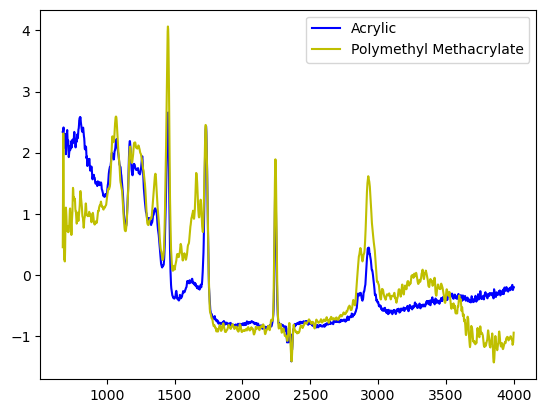

In [69]:
plt.plot(df_fltered.query('file_name == @fn')['wavelength'],
                 -df_fltered.query('file_name == @fn')['intensity'],
                 alpha=1,
                 color='b',
                 label='Acrylic')

plt.plot(df_fltered2.query('file_name == @fn2')['wavelength'],
                 -df_fltered2.query('file_name == @fn2')['intensity'],
                 alpha=1,
                 color='y',
                 label='Polymethyl Methacrylate')

plt.legend()

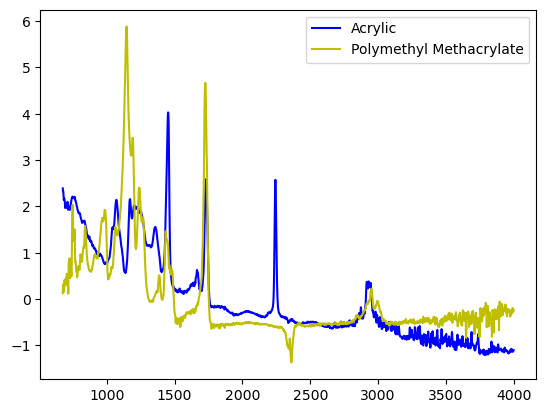

In [70]:
fn = file_name_list[0]
fn2 = file_name_list2[0]
plt.plot(df_fltered.query('file_name == @fn')['wavelength'],
                 -df_fltered.query('file_name == @fn')['intensity'],
                 alpha=1,
                 color='b',
                 label='Acrylic')

plt.plot(df_fltered2.query('file_name == @fn2')['wavelength'],
                 -df_fltered2.query('file_name == @fn2')['intensity'],
                 alpha=1,
                 color='y',
                 label='Polymethyl Methacrylate')

plt.legend()

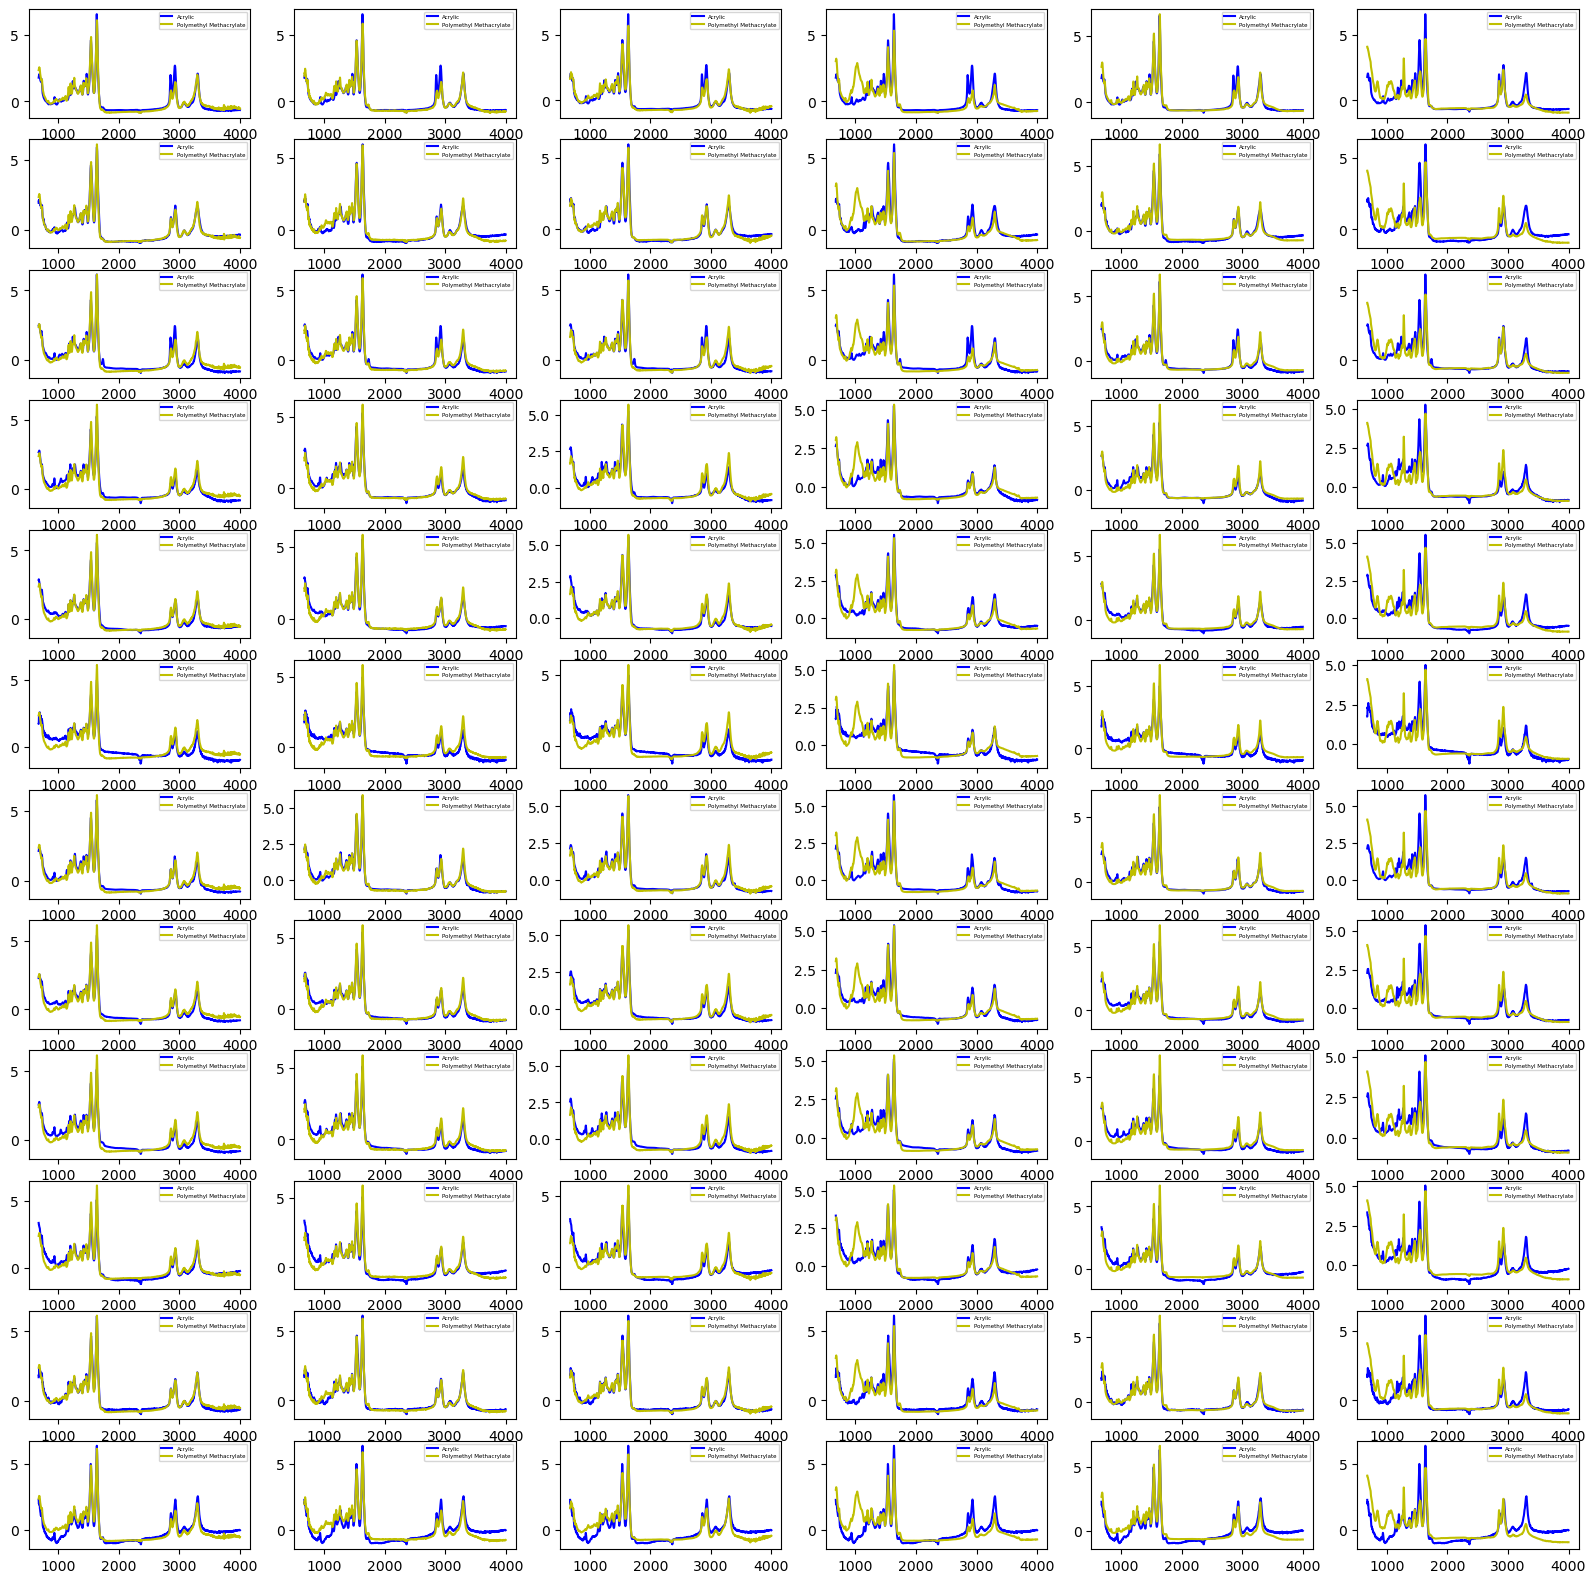

In [43]:
fig, ax = plt.subplots(nrows=12, ncols=6)
fig.set_figheight(20)
fig.set_figwidth(20)
df_fltered = df_spectra_flopp.query('polymer == "Nylon"')
df_fltered2 = df_spectra_flopp.query('polymer == "Polyamide"')
        #df_fltered = df_fltered.query('wavelength > 674 and wavelength < 4000')
file_name_list = df_fltered['file_name'].drop_duplicates().to_numpy()
file_name_list2 = df_fltered2['file_name'].drop_duplicates().to_numpy()
n_files = len(file_name_list)
n_files2 = len(file_name_list)
        
#if ds == 'flopp':
#color = 'y'
#else:
#color = 'b'

fn = file_name_list[5]
fn2 = file_name_list2[1]
        
for i, fn in enumerate(file_name_list):
    for j, fn2 in enumerate(file_name_list2):
        
        ax[i, j].plot(df_fltered.query('file_name == @fn')['wavelength'],
                 -df_fltered.query('file_name == @fn')['intensity'],
                 alpha=1,
                 color='b',
                 label='Acrylic')

        ax[i, j].plot(df_fltered2.query('file_name == @fn2')['wavelength'],
                 -df_fltered2.query('file_name == @fn2')['intensity'],
                 alpha=1,
                 color='y',
                 label='Polymethyl Methacrylate')

        ax[i, j].legend(fontsize=4)
        

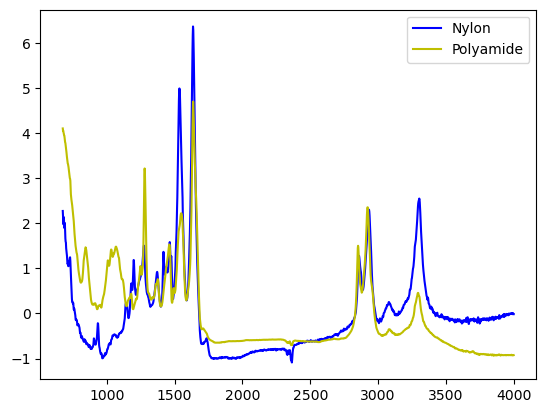

In [44]:
plt.plot(df_fltered.query('file_name == @fn')['wavelength'],
                 -df_fltered.query('file_name == @fn')['intensity'],
                 alpha=1,
                 color='b',
                 label='Nylon')

plt.plot(df_fltered2.query('file_name == @fn2')['wavelength'],
                 -df_fltered2.query('file_name == @fn2')['intensity'],
                 alpha=1,
                 color='y',
                 label='Polyamide')

plt.legend()

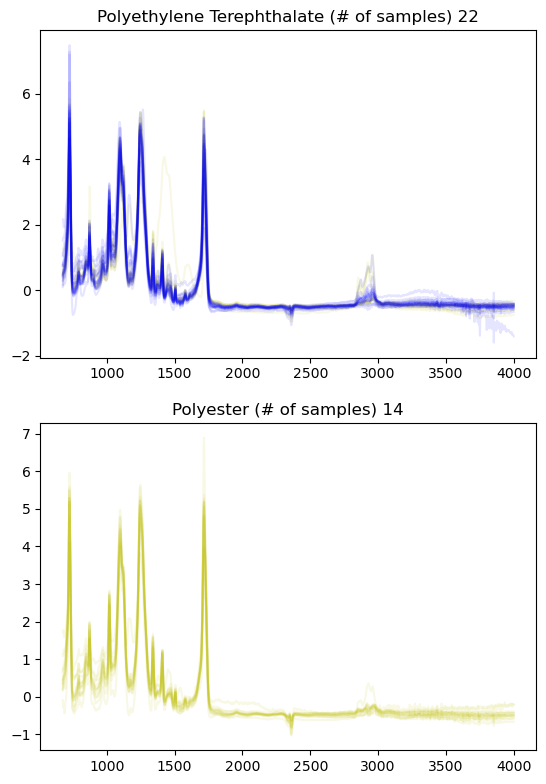

In [42]:
fig, ax = plt.subplots(nrows=2)
#fig.set_figheight(40)
#fig.set_figwidth(20)
for j, ds in enumerate(['flopp', 'flopp_e']):
    for i, p in enumerate(['Polyethylene Terephthalate', 'Polyester']):
        
        df_fltered = df_spectra_flopp.query('polymer == @p and data_source == @ds')
        df_fltered = df_fltered.query('wavelength > 674 and wavelength < 4000')
        file_name_list = df_fltered['file_name'].drop_duplicates().to_numpy()
        n_files = len(file_name_list)
        
        if ds == 'flopp':
            color = 'y'
        else:
            color = 'b'

        for fn in file_name_list:
            _ = ax[i].plot(df_fltered.query('file_name == @fn')['wavelength'],
                            -df_fltered.query('file_name == @fn')['intensity'],
                           alpha=0.1,
                           color=color)
            _ = ax[i].title.set_text(p + ' (# of samples) ' + str(n_files))
            #_ = ax[i, j].plot()
            #_ = ax[i, j].plot()
            #_ = ax[i, j].legend()
            #
        
fig.subplots_adjust(left=None, 
                            bottom=0, 
                            right=None, 
                            top=1.5, 
                            wspace=None, 
                            hspace=None)

In [72]:
X_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,3:]
X_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,3:]
y_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,1]
y_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,1]

# construct folds: -----------------------------------------------------------
idx = sample(range(y_train.shape[0]), y_train.shape[0])
X_train = X_train.reset_index(drop=True)
X_train_ = X_train.copy()
y_train = y_train.reset_index(drop=True)
X_train_['fold'] = np.array(idx) // (X_train_.shape[0]/10)
folds_size = pd.DataFrame(X_train_.groupby('fold').size())
folds_size.columns = ['Size']
#display(folds_size)

# folds as array indices
folds = []
n = y_train.shape[0]
rows = np.arange(n)
for fold in range(10):
    train = np.asarray(X_train_['fold'] != fold).nonzero()[0]
    test = np.asarray(X_train_['fold'] == fold).nonzero()[0]
    folds.append((train, test))
    
x_train = X_train.to_numpy()
y_train_ = y_train.to_numpy()
n, p = x_train.shape

In [74]:
clf = model_logReg(C=7)
clf.train_data(x_train, y_train_)
clf.fit()
#clf.cv(folds, list(range(1, 15)), plot_=True)
y_test_hat = clf.predict(X_test)
clf.score(X_test, y_test)

0.8

In [75]:
y_train_df = pd.DataFrame(y_train)
y_train_df['count'] = 1
classes_count_train = y_train_df.groupby('polymer').count()

pred_test = pd.DataFrame({'true_poly': np.asarray(y_test), 
                       'correct_class':y_test_hat == np.asarray(y_test)})

pred_test_table = pd.concat([classes_count_train,
           pred_test.groupby('true_poly').count(),
           pred_test.groupby('true_poly').mean()], axis=1)

pred_test_table.columns = ['count_train', 'count_test', 'accurasy_test']
pred_test_table.loc[np.logical_not(np.isnan(pred_test_table['accurasy_test'])), :]#.query('accurasy_test > 0')
#pred_test_table

,count_train,count_test,accurasy_test
Acrylonitrile Butadiene Styrene,14.0,1.0,1.000000
Cotton,14.0,12.0,1.000000
Polycarbonate,8.0,1.0,1.000000
Polyethylene,18.0,49.0,0.918367
Polyethylene Terephthalate,11.0,22.0,0.409091
Polyethylene Vinyl Acetate,10.0,5.0,1.000000
Polypropylene,19.0,66.0,0.878788
Polystyrene,14.0,12.0,0.833333
Polyurethane,13.0,6.0,1.000000
Polyvinyl Chloride,9.0,9.0,1.000000


In [76]:
nan_train = np.logical_not(np.isnan(pred_test_table['count_train']))
(pred_test_table.loc[nan_train, 'count_test'] * 
 pred_test_table.loc[nan_train, 'accurasy_test']).sum() / pred_test_table.loc[nan_train, 'count_test'].sum()


0.8524590163934426

In [60]:
set_classes = set(y_test)
set_classes = set_classes.union(set(y_test_hat))
#set_classes = ['Acrylic', 'Polymethyl Methacrylate']
classes_test_hat = np.array(list(set_classes))
classes_test_hat.sort()

conf_mat = confusion_matrix(y_test, y_test_hat, labels=classes_test_hat)
conf_mat = conf_mat - np.diag(np.diag(conf_mat))

conf_mat_df = pd.DataFrame(conf_mat)
conf_mat_df.columns = classes_test_hat
conf_mat_df['true_polymer'] = classes_test_hat
#conf_mat_df = conf_mat_df.reset_index()
conf_mat_df = conf_mat_df.melt(id_vars=['true_polymer'])
conf_mat_df.columns = ['true_polymer', 'pred_polymer', 'miss_class']
(conf_mat_df.
 query('miss_class > 0').
 merge(pred_test_table.loc[:,'count_test'], 
       left_on='true_polymer', 
       right_index=True).
 sort_values(['true_polymer', 'pred_polymer']))

,true_polymer,pred_polymer,miss_class,count_test
211,Cellulose Acetate,Polyethylene Vinyl Acetate,2,2.0
213,Ethylene Acrylic Acid,Polyethylene Vinyl Acetate,1,1.0
101,Polyamide,Nylon,6,6.0
66,Polyethylene,Cotton,1,49.0
294,Polyethylene,Polyurethane,1,49.0
332,Polyethylene,Rubber,2,49.0
162,Polyethylene Terephthalate,Polyester,13,22.0
12,Polymethyl Methacrylate,Acrylic,1,2.0
297,Polymethyl Methacrylate,Polyurethane,1,2.0
70,Polypropylene,Cotton,1,66.0


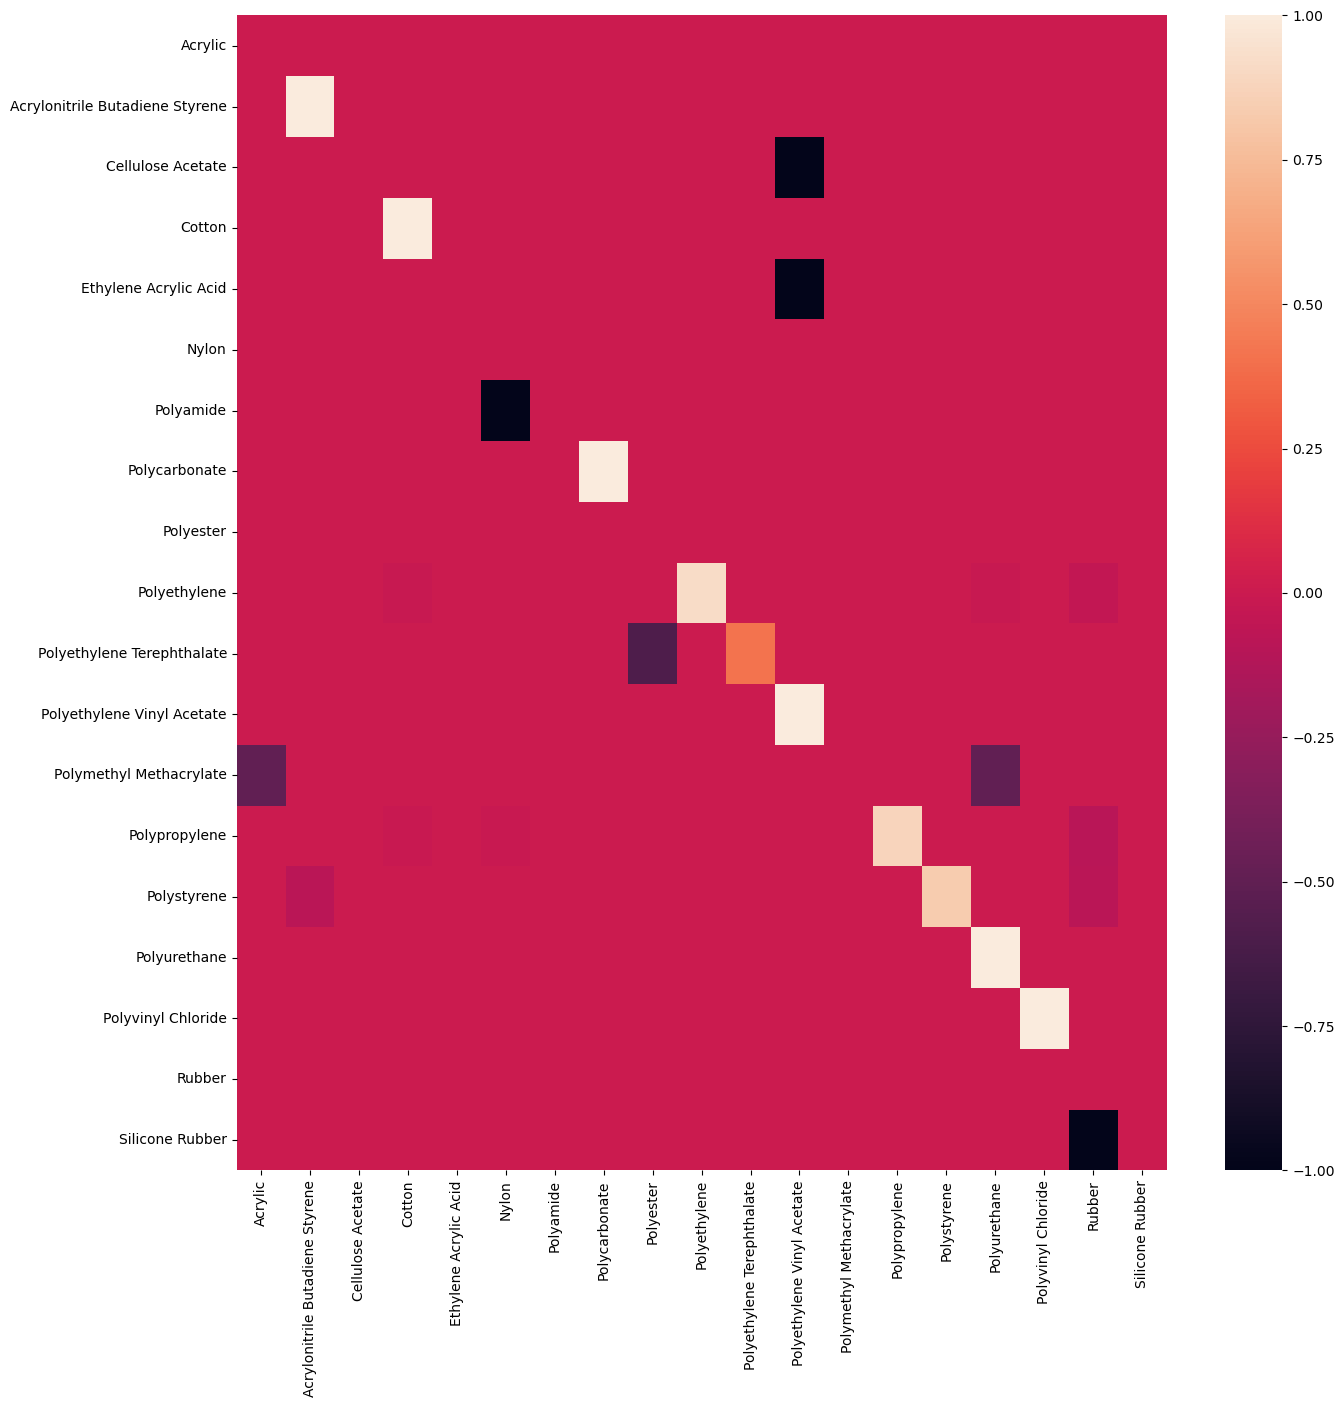

In [61]:
set_classes = set(y_test)
set_classes = set_classes.union(set(y_test_hat))
#set_classes = ['Acrylic', 'Polymethyl Methacrylate']
classes_test_hat = np.array(list(set_classes))
classes_test_hat.sort()

conf_mat = confusion_matrix(y_test, y_test_hat, labels=classes_test_hat)
row_sums = conf_mat.sum(axis=1)
row_sums[row_sums == 0] = 1
conf_mat = conf_mat / row_sums[:, np.newaxis]
conf_mat = 2*np.diag(np.diag(conf_mat)) - conf_mat

conf_mat_df = pd.DataFrame(conf_mat)
conf_mat_df.columns = classes_test_hat
conf_mat_df.index = classes_test_hat


fig, ax = plt.subplots(figsize=(15,15))    
sns.heatmap(conf_mat_df); #, xticklabels=True, yticklabels=True

In [62]:
y_train_[y_train_ == 'Nylon'] = 'Polyamide'
y_train_[y_train_ == 'Polyester'] = 'Polyethylene Terephthalate'
#y_train_[y_train_ == 'Acrylic'] = 'Polymethyl Methacrylate'

In [63]:
clf.train_data(x_train, y_train_)
clf.fit()
#clf.cv(folds, list(range(1, 15)), plot_=True)
y_test_hat = clf.predict(X_test)
clf_score = clf.score(X_test, y_test)
clf_score

0.8871794871794871

best C: 2.00


(2.0, 0.9514619883040936)

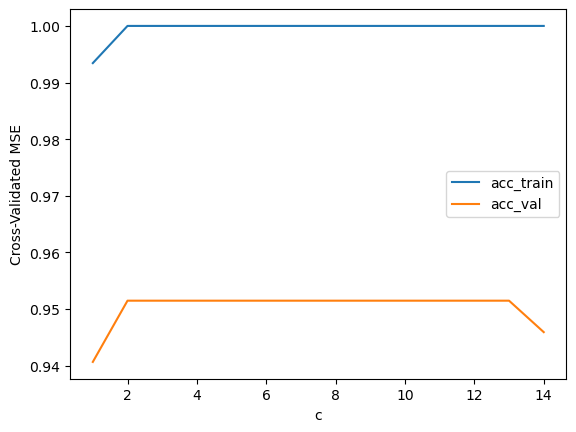

In [326]:
#clf.cv(folds, list(range(1, 15)), plot_=True)

In [22]:
conf_mat = confusion_matrix(y_test, y_test_hat, labels=classes_test_hat)
conf_mat = conf_mat - np.diag(np.diag(conf_mat))

conf_mat_df = pd.DataFrame(conf_mat)
conf_mat_df.columns = classes_test_hat
conf_mat_df['true_polymer'] = classes_test_hat
#conf_mat_df = conf_mat_df.reset_index()
conf_mat_df = conf_mat_df.melt(id_vars=['true_polymer'])
conf_mat_df.columns = ['true_polymer', 'pred_polymer', 'miss_class']
(conf_mat_df.
 query('miss_class > 0').
 merge(pred_test_table.loc[:,'count_test'], 
       left_on='true_polymer', 
       right_index=True).
 sort_values(['true_polymer', 'pred_polymer']))

,true_polymer,pred_polymer,miss_class,count_test
211,Cellulose Acetate,Polyethylene Vinyl Acetate,2,2.0
213,Ethylene Acrylic Acid,Polyethylene Vinyl Acetate,1,1.0
66,Polyethylene,Cotton,1,49.0
294,Polyethylene,Polyurethane,1,49.0
332,Polyethylene,Rubber,3,49.0
12,Polymethyl Methacrylate,Acrylic,1,2.0
297,Polymethyl Methacrylate,Polyurethane,1,2.0
70,Polypropylene,Cotton,1,66.0
127,Polypropylene,Polyamide,1,66.0
336,Polypropylene,Rubber,6,66.0


In [64]:
y_train_df = pd.DataFrame(y_train)
y_train_df['count'] = 1
classes_count_train = y_train_df.groupby('polymer').count()

pred_test = pd.DataFrame({'true_poly': np.asarray(y_test), 
                       'correct_class':y_test_hat == np.asarray(y_test)})

pred_test_table = pd.concat([classes_count_train,
           pred_test.groupby('true_poly').count(),
           pred_test.groupby('true_poly').mean()], axis=1)

pred_test_table.columns = ['count_train', 'count_test', 'accurasy_test']
pred_test_table.loc[np.logical_not(np.isnan(pred_test_table['accurasy_test'])), :]#.query('accurasy_test > 0')

,count_train,count_test,accurasy_test
Acrylonitrile Butadiene Styrene,14.0,1.0,1.000000
Cotton,14.0,12.0,1.000000
Polyamide,12.0,6.0,1.000000
Polycarbonate,8.0,1.0,1.000000
Polyethylene,18.0,49.0,0.897959
Polyethylene Terephthalate,25.0,22.0,1.000000
Polyethylene Vinyl Acetate,10.0,5.0,1.000000
Polypropylene,19.0,66.0,0.878788
Polystyrene,14.0,12.0,0.833333
Polyurethane,13.0,6.0,1.000000


In [65]:
nan_train = np.logical_not(np.isnan(pred_test_table['count_train']))
(pred_test_table.loc[nan_train, 'count_test'] * 
 pred_test_table.loc[nan_train, 'accurasy_test']).sum() / pred_test_table.loc[nan_train, 'count_test'].sum()

0.9153439153439153

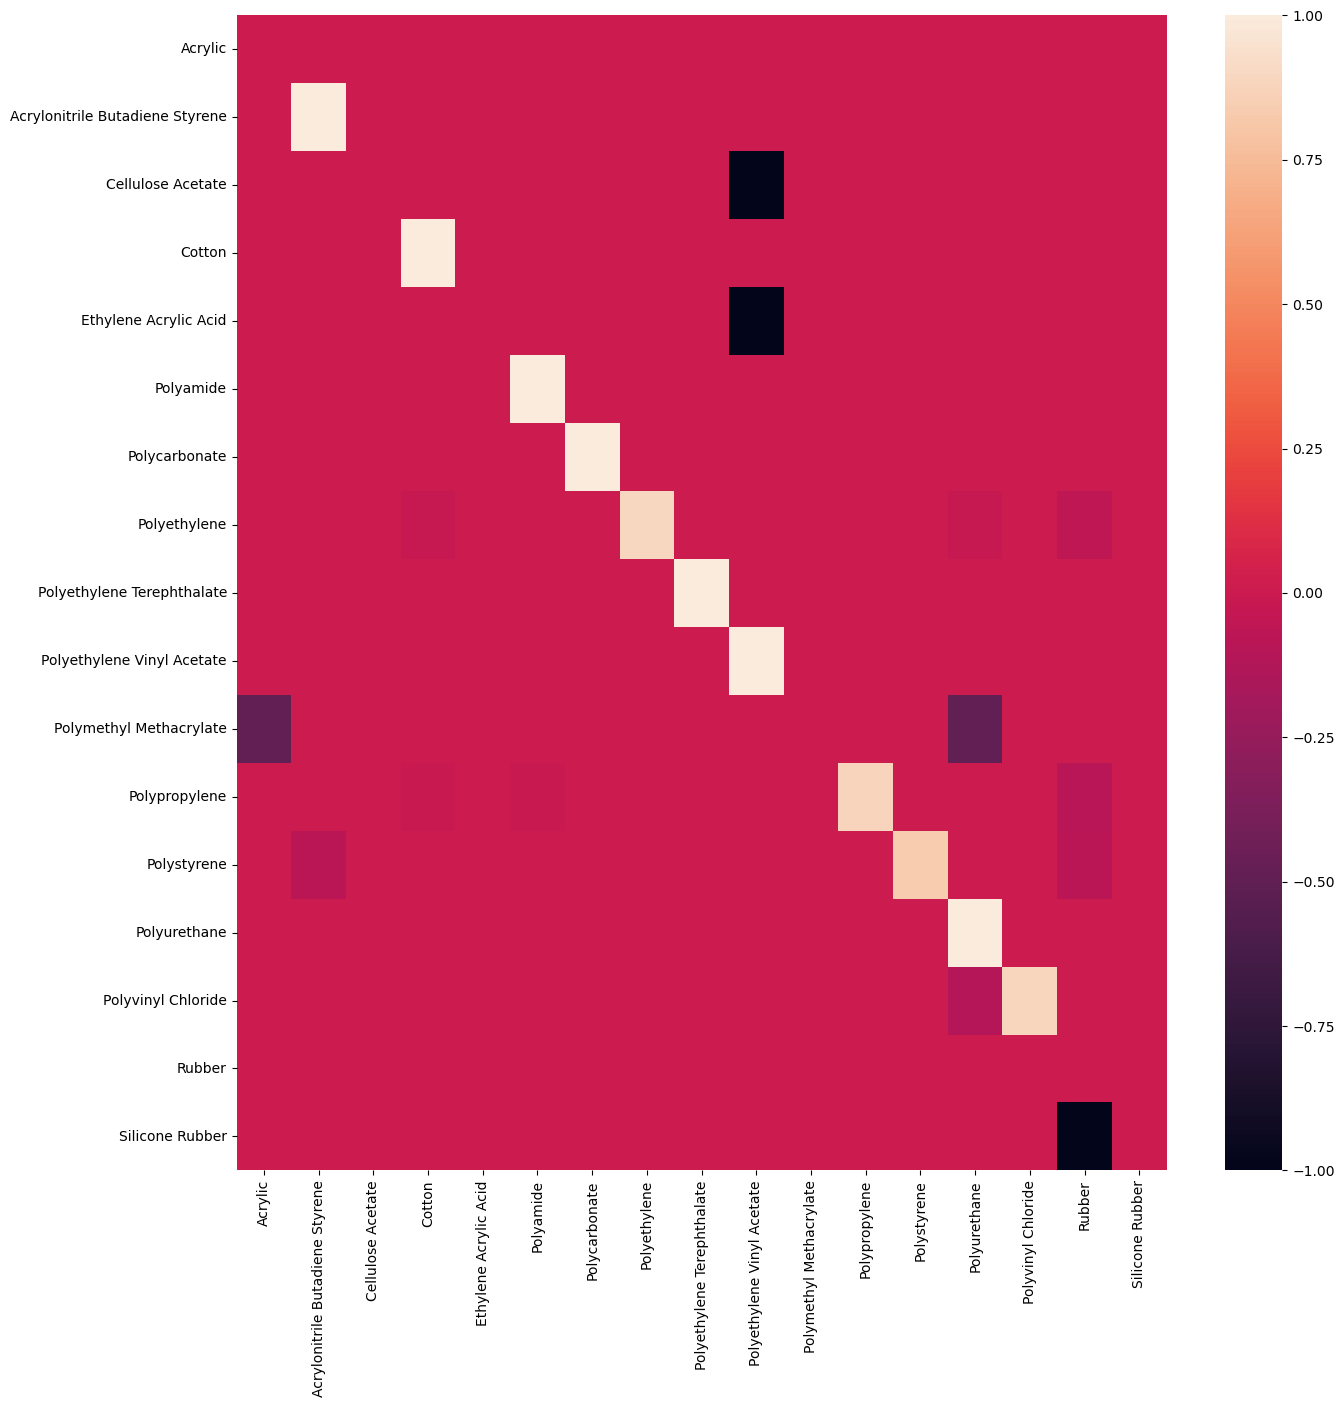

In [66]:
set_classes = set(y_test)
set_classes = set_classes.union(set(y_test_hat))
#set_classes = ['Acrylic', 'Polymethyl Methacrylate']
classes_test_hat = np.array(list(set_classes))
classes_test_hat.sort()

conf_mat = confusion_matrix(y_test, y_test_hat, labels=classes_test_hat)
row_sums = conf_mat.sum(axis=1)
row_sums[row_sums == 0] = 1
conf_mat = conf_mat / row_sums[:, np.newaxis]
conf_mat = 2*np.diag(np.diag(conf_mat)) - conf_mat

conf_mat_df = pd.DataFrame(conf_mat)
conf_mat_df.columns = classes_test_hat
conf_mat_df.index = classes_test_hat


fig, ax = plt.subplots(figsize=(15,15))    
sns.heatmap(conf_mat_df); #, xticklabels=True, yticklabels=True

In [26]:
rf = model_randF(max_depth=10,
                 n_estimators=60)
rf.train_data(x_train, y_train_)
rf.fit()
rf_score = rf.score(X_test, y_test)

best max_depth: 15.00
best n_estimators: 110.00


(15.0, 110, 0.935672514619883)

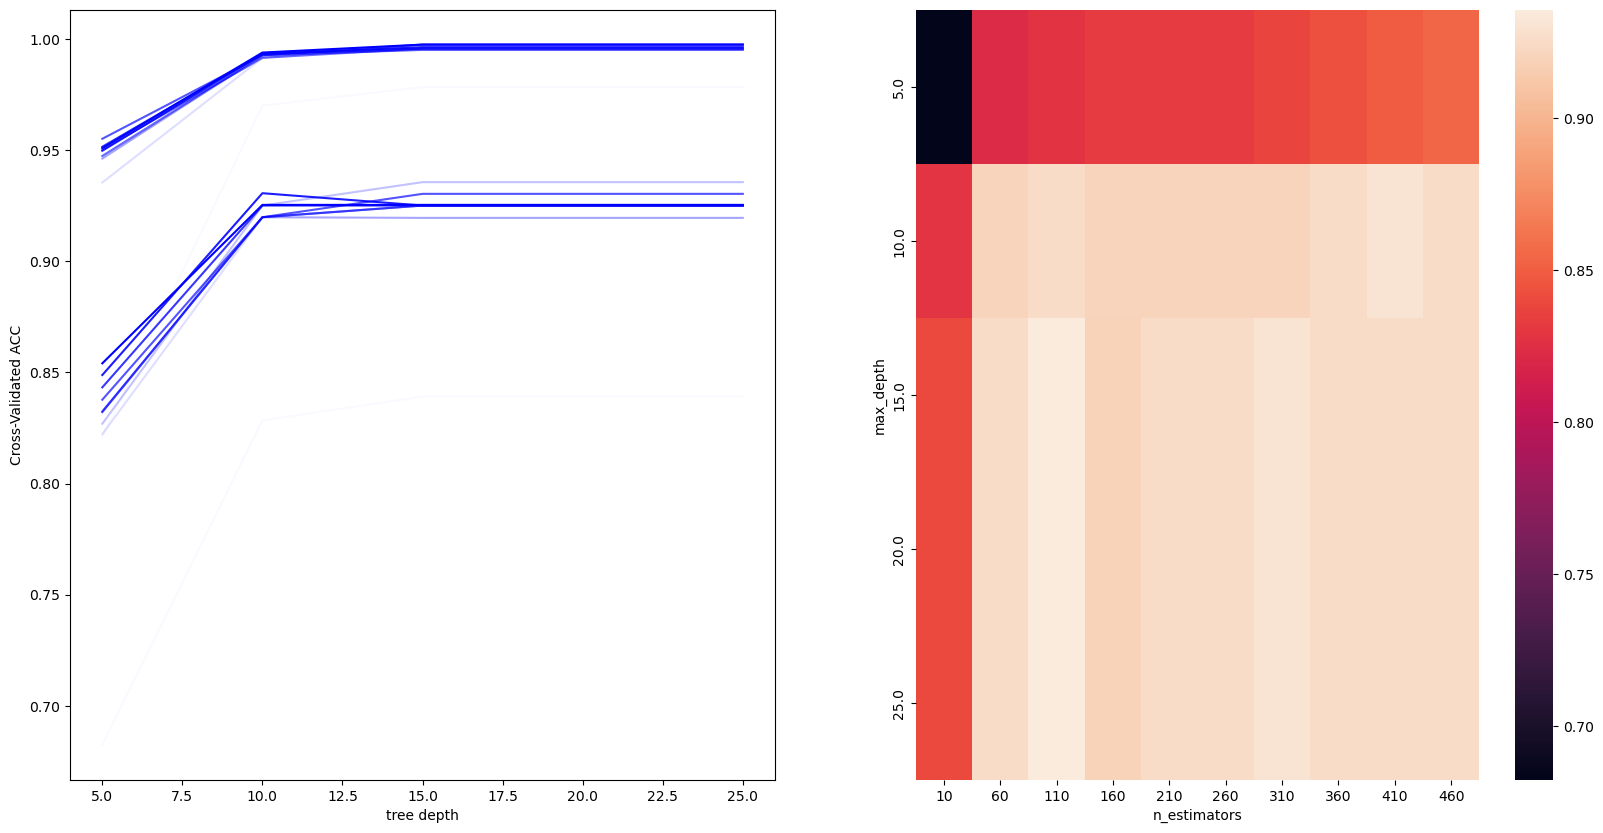

In [32]:
#rf.cv(folds, (5, 10, 20, 15, 20, 25, None), np.arange(10, 500, 50), plot_=True)

In [27]:
knn = model_knn(n_neighbors=1)
knn.train_data(x_train, y_train_)
knn.fit()
knn_score = knn.score(X_test, y_test)
#knn.cv(folds, (1, 2, 5, 10), plot_=True)

In [29]:
svm = SVC(gamma='auto', probability=True)
svm.fit(X_train, y_train)
svm_score = svm.score(X_test, y_test)
#svm.score(X_train, y_train)

In [80]:
kernel = 1.0 * RBF(1.0)
gpc = GaussianProcessClassifier(random_state=0).fit(X_train, y_train)
gpc.score(X_train, y_train), gpc.score(X_test, y_test)

(1.0, 0.2923076923076923)

In [77]:
pd.DataFrame({'model': ['logistic', 'random forest', 'knn (k=1)', 'SVM'],
              'cv_accuracy_flopp':[0.95,0.94,0.93,0.97], 
              'accuracy_flopp_e':np.round(np.array([clf_score, rf_score, knn_score, svm_score]), 2)})



,model,cv_accuracy_flopp,accuracy_flopp_e
0,logistic,0.95,0.89
1,random forest,0.94,0.84
2,knn (k=1),0.93,0.79
3,SVM,0.97,0.84
